In [3]:
# Import Python Libraries
import numpy as np
# Take two sets of patterns:
# Set A: Input Pattern
x1 = np.array([1, 1, 1, 1, 1, 1]).reshape(6, 1)
x2 = np.array([-1,
-1,
-1,
-1,
-1,
-1]).reshape(6, 1)
x3 = np.array([1, 1, -1, -1, 1, 1]).reshape(6, 1)
x4 = np.array([-1,
-1,
-1, 1, 1,
-1]).reshape(6, 1)
# Set B: Target Pattern
y1 = np.array([1, 1, 1]).reshape(3, 1)
y2 = np.array([-1,
-1,
-1]).reshape(3, 1)
y3 = np.array([1,
-1, 1]).reshape(3, 1)
y4 = np.array([-1, 1,
-1]).reshape(3, 1)
'''
print("Set A: Input Pattern, Set B: Target Pattern")
print("\nThe input for pattern 1 is")
print(x1)
print("\nThe target for pattern 1 is")
print(y1)
print("\nThe input for pattern 2 is")
print(x2)
print("\nThe target for pattern 2 is")
print(y2)
print("\nThe input for pattern 3 is")
print(x3)
print("\nThe target for pattern 3 is")
print(y3)
print("\nThe input for pattern 4 is")
print(x4)
print("\nThe target for pattern 4 is")
print(y4)
print("\n------------------------------")
'''
# Calculate weight Matrix: W
inputSet = np.concatenate((x1, x2, x3, x4), axis=1)
targetSet = np.concatenate((y1.T, y2.T, y3.T, y4.T), axis=0)
print("\nWeight matrix:")
weight = np.dot(inputSet, targetSet)
print(weight)
print("\n------------------------------")
# Testing Phase
# Test for Input Patterns: Set A
print("\nTesting for input patterns: Set A")
def testInputs(x, weight):
    # Multiply the input pattern with the weight matrix
    # (weight.T X x)
    y = np.dot(weight.T, x)
    y[y < 0] = -1
    y[y >= 0] = 1
    return np.array(y)
print("\nOutput of input pattern 1")
print(testInputs(x1, weight))
print("\nOutput of input pattern 2")
print(testInputs(x2, weight))
print("\nOutput of input pattern 3")
print(testInputs(x3, weight))
print("\nOutput of input pattern 4")
print(testInputs(x4, weight))
# Test for Target Patterns: Set B
print("\nTesting for target patterns: Set B")
def testTargets(y, weight):
    # Multiply the target pattern with the weight matrix
    # (weight X y)
    x = np.dot(weight, y)
    x[x <= 0] = -1
    x[x > 0] = 1
    return np.array(x)
print("\nOutput of target pattern 1")
print(testTargets(y1, weight))
print("\nOutput of target pattern 2")
print(testTargets(y2, weight))
print("\nOutput of target pattern 3")
print(testTargets(y3, weight))
print("\nOutput of target pattern 4")
print(testTargets(y4, weight))


Weight matrix:
[[4 0 4]
 [4 0 4]
 [2 2 2]
 [0 4 0]
 [2 2 2]
 [4 0 4]]

------------------------------

Testing for input patterns: Set A

Output of input pattern 1
[[1]
 [1]
 [1]]

Output of input pattern 2
[[-1]
 [-1]
 [-1]]

Output of input pattern 3
[[ 1]
 [-1]
 [ 1]]

Output of input pattern 4
[[-1]
 [ 1]
 [-1]]

Testing for target patterns: Set B

Output of target pattern 1
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Output of target pattern 2
[[-1]
 [-1]
 [-1]
 [-1]
 [-1]
 [-1]]

Output of target pattern 3
[[ 1]
 [ 1]
 [ 1]
 [-1]
 [ 1]
 [ 1]]

Output of target pattern 4
[[-1]
 [-1]
 [-1]
 [ 1]
 [-1]
 [-1]]


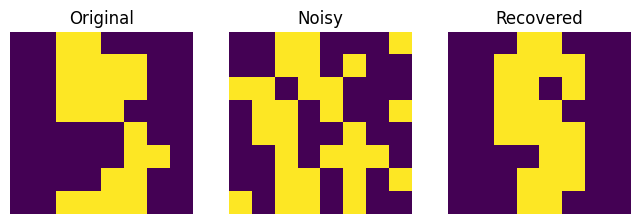

Actual: 5
Predicted: 0


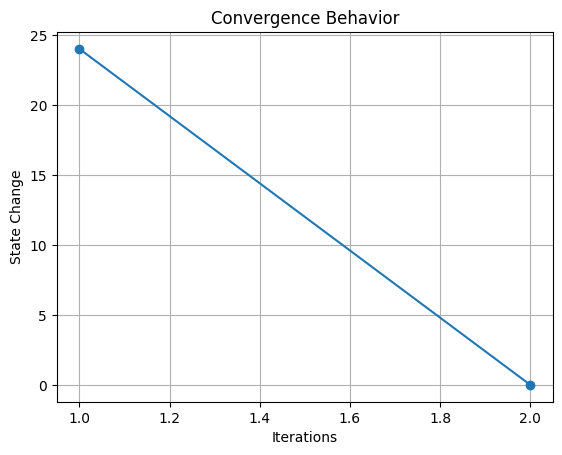

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
# Load dataset
digits = load_digits()
X_data = digits.images
y_data = digits.target
# Preprocess images
def preprocess_images(X):
    X_flat = X.reshape(X.shape[0], -1)
    return np.where(X_flat > 8, 1, -1)
# Convert labels to bipolar
def bipolar_labels(y, num_classes=10):
    Y = -np.ones((len(y), num_classes))
    for i, label in enumerate(y):
        Y[i][label] = 1
    return Y
X = preprocess_images(X_data)
Y = bipolar_labels(y_data)
# Train BAM
def train_bam(X_patterns, Y_patterns):
    W = np.zeros((X_patterns.shape[1], Y_patterns.shape[1]))
    for i in range(len(X_patterns)):
        x = X_patterns[i].reshape(-1, 1)
        y = Y_patterns[i].reshape(-1, 1)
        W += np.dot(x, y.T)
    return W
W = train_bam(X[:100], Y[:100])
# Activation
def sign(x):
    return np.where(x >= 0, 1, -1)
# Recall
def recall_bam(X, W, max_iter=10):
    x = X.copy()
    history = []
    for _ in range(max_iter):
        y = sign(np.dot(x, W))
        x_new = sign(np.dot(y, W.T))
        change = np.sum(x != x_new)
        history.append(change)
        if np.array_equal(x, x_new):
            break
        x = x_new
    return x, y, history
# Add noise
def add_noise(x, noise_level=0.3):
    noisy = x.copy()
    n_flip = int(len(x) * noise_level)
    indices = np.random.choice(len(x), n_flip, replace=False)
    noisy[indices] *= -1
    return noisy
# Visualization
def plot_images(original, noisy, recovered):
    fig, axes = plt.subplots(1, 3, figsize=(8, 3))
    axes[0].imshow(original.reshape(8, 8))
    axes[0].set_title("Original")
    axes[1].imshow(noisy.reshape(8, 8))
    axes[1].set_title("Noisy")
    axes[2].imshow(recovered.reshape(8, 8))
    axes[2].set_title("Recovered")
    for ax in axes:
        ax.axis('off')
    plt.savefig('1-1.svg')
    plt.show()
# Test
idx = 5
original = X[idx]
noisy = add_noise(original)
recovered_x, recovered_y, history = recall_bam(noisy, W)
plot_images(original, noisy, recovered_x)
print("Actual:", y_data[idx])
print("Predicted:", np.argmax(recovered_y))
# Convergence plot
plt.plot(range(1, len(history) + 1), history, marker='o')
plt.xlabel("Iterations")
plt.ylabel("State Change")
plt.title("Convergence Behavior")
plt.grid()
plt.savefig('1-2.svg')
plt.show()